# Black-Scholes-Merton pricing for a European stock option

This notebook prices a European **call and put** on a stock with the Black-Scholes-Merton model,
using volatility estimated from Yahoo Finance prices. It covers:

1. **Parameters**: everything you might change, in one place
2. **Market data and volatility**: 1-year daily and 30-day hourly estimates
3. **Option prices**: call, put and a put-call parity check
4. **The Greeks**: Delta, Gamma, Vega, Theta and Rho, as a table and as charts
5. **Implied volatility**: backed out of a market price, Newton-Raphson with a bisection fallback

Model (continuous dividend yield $q$):

$$d_1 = \frac{\ln(S_0/K) + (r - q + \tfrac12\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

$$C = S_0e^{-qT}N(d_1) - Ke^{-rT}N(d_2), \qquad P = Ke^{-rT}N(-d_2) - S_0e^{-qT}N(-d_1)$$

## 0. Setup

Run this cell once. It installs any of the required packages that are missing from the
Python environment this notebook runs in (it does nothing if they are already installed).

In [1]:
import importlib.util, subprocess, sys

required = {"yfinance": "yfinance", "matplotlib": "matplotlib", "scipy": "scipy",
            "pandas": "pandas", "numpy": "numpy"}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *missing])
    print("Done. If an import below still fails, restart the kernel and run again.")
else:
    print("All required packages are installed.")

Installing: yfinance, matplotlib, scipy, pandas, numpy
Done. If an import below still fails, restart the kernel and run again.


## 1. Parameters

In [2]:
import datetime as dt

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import brentq
from scipy.stats import norm

# ---- inputs (edit these) -------------------------------------------------
TICKER = "NVO"     # Yahoo Finance ticker
K      = 100.0     # strike price (set to None to use the at-the-money strike)
T      = 0.5       # time to maturity in years
r      = None      # risk-free rate, e.g. 0.04 (None = 13-week US T-bill yield from Yahoo)
q      = None      # dividend yield, e.g. 0.045 (None = last 12 months of dividends / spot)
VOL_SOURCE = "daily_1y"   # which estimate to price with: "daily_1y" or "hourly_30d"

Matplotlib is building the font cache; this may take a moment.


## 2. Market data and volatility

Volatility is the standard deviation of log returns, scaled to a year by the square root of the
number of return periods in a year:

* **Daily bars:** $\sigma = \text{std}(\ln S_t/S_{t-1}) \times \sqrt{252}$
* **Hourly bars:** $\sigma = \text{std}(\ln S_t/S_{t-1}) \times \sqrt{252 \times \text{bars per day}}$

The original notebook scaled hourly returns by $\sqrt{252}$, which treated each hour as a whole
trading day and understated volatility by roughly $\sqrt{7} \approx 2.6\times$.

In [ ]:
def close_series(df: pd.DataFrame) -> pd.Series:
    # Newer yfinance returns (field, ticker) column pairs even for one ticker; flatten to a Series.
    close = df["Close"]
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]
    return close.dropna()


def annualized_vol(close: pd.Series, periods_per_year: float) -> float:
    log_ret = np.log(close / close.shift(1)).dropna()
    return float(log_ret.std() * np.sqrt(periods_per_year))


# 1 year of daily closes
daily = close_series(yf.download(TICKER, period="1y", interval="1d",
                                 auto_adjust=True, progress=False))
if daily.empty:
    raise RuntimeError(f"No price data returned for {TICKER!r}. Check the ticker and your connection.")

S0 = float(daily.iloc[-1])
vol_daily = annualized_vol(daily, 252)

# 30 days of hourly closes
hourly = close_series(yf.download(TICKER, period="30d", interval="1h",
                                  auto_adjust=True, progress=False))
bars_per_day = hourly.groupby(hourly.index.date).size().mean()
vol_hourly = annualized_vol(hourly, 252 * bars_per_day)

if K is None:
    K = round(S0)

# Risk-free rate: 13-week T-bill yield 
r_source = "your input"
if r is None:
    try:
        irx = close_series(yf.download("^IRX", period="5d", auto_adjust=True, progress=False))
        r, r_source = float(np.log(1 + irx.iloc[-1] / 100)), "13-week T-bill (^IRX)"
    except Exception:
        r, r_source = 0.04, "fallback (T-bill download failed)"

# Dividend yield
q_source = "your input"
if q is None:
    try:
        divs = yf.Ticker(TICKER).dividends
        cutoff = pd.Timestamp.now(tz=divs.index.tz) - pd.DateOffset(years=1)
        q = float(np.log(1 + divs[divs.index > cutoff].sum() / S0))
        q_source = "trailing 12M dividends"
    except Exception:
        q, q_source = 0.0, "fallback (dividend download failed)"

sigma = {"daily_1y": vol_daily, "hourly_30d": vol_hourly}[VOL_SOURCE]

pd.Series({
    "Spot price S0": f"{S0:,.2f}",
    "Strike K": f"{K:,.2f}",
    "Moneyness S0/K": f"{S0 / K:.3f}",
    "Volatility, 1Y daily": f"{vol_daily:.2%}",
    f"Volatility, 30D hourly ({bars_per_day:.1f} bars/day)": f"{vol_hourly:.2%}",
    "Volatility used": f"{sigma:.2%} ({VOL_SOURCE})",
    "Risk-free rate r": f"{r:.2%} ({r_source})",
    "Dividend yield q": f"{q:.2%} ({q_source})",
}, name=TICKER).to_frame()

,NVO
Spot price S0,40.97
Strike K,100.00
Moneyness S0/K,0.410
"Volatility, 1Y daily",45.85%
"Volatility, 30D hourly (7.0 bars/day)",32.34%
Volatility used,45.85% (daily_1y)
Risk-free rate r,4.07% (13-week T-bill (^IRX))
Dividend yield q,4.43% (trailing 12M dividends)


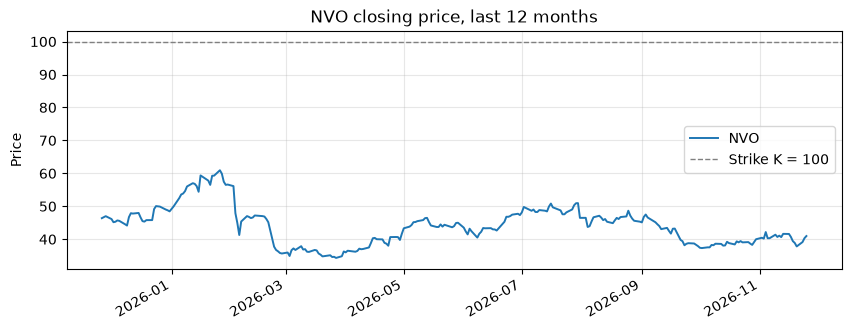

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
daily.plot(ax=ax, lw=1.4)
ax.axhline(K, ls="--", c="grey", lw=1, label=f"Strike K = {K:,.0f}")
ax.set(title=f"{TICKER} closing price, last 12 months", ylabel="Price", xlabel="")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 3. Option prices

In [ ]:
def _d1_d2(S, K, T, r, q, sigma):
    S = np.asarray(S, dtype=float)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)


def bsm_price(S, K, T, r, sigma, q=0.0, kind="call"):
    d1, d2 = _d1_d2(S, K, T, r, q, sigma)
    if kind == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    if kind == "put":
        return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
    raise ValueError("kind must be 'call' or 'put'")


call = float(bsm_price(S0, K, T, r, sigma, q, "call"))
put  = float(bsm_price(S0, K, T, r, sigma, q, "put"))

# Put-call parity: C - P = S0*e^(-qT) - K*e^(-rT)
parity_gap = (call - put) - (S0 * np.exp(-q * T) - K * np.exp(-r * T))

print(f"{TICKER}  S0={S0:.2f}  K={K:.2f}  T={T}y  r={r:.2%}  q={q:.2%}  sigma={sigma:.2%}\n")
print(f"European call : {call:10.4f}")
print(f"European put  : {put:10.4f}")
print(f"Put-call parity difference: {parity_gap:.2e}")

NVO  S0=40.97  K=100.00  T=0.5y  r=4.07%  q=4.43%  sigma=45.85%

European call :     0.0176
European put  :    57.9294
Put-call parity difference: 0.00e+00


## 4. The Greeks

Each Greek measures how the option price responds to one input while the others stay fixed.

| Greek | Measures sensitivity to | Call | Put |
|---|---|---|---|
| **Delta** $\Delta$ | spot price | $e^{-qT}N(d_1)$ | $e^{-qT}\,(N(d_1)-1)$ |
| **Gamma** $\Gamma$ | change in Delta | $\dfrac{e^{-qT}\,n(d_1)}{S_0\sigma\sqrt{T}}$ | same as call |
| **Vega** $\nu$ | volatility | $S_0e^{-qT}\,n(d_1)\sqrt{T}$ | same as call |
| **Theta** $\Theta$ | time passing | $-\dfrac{S_0e^{-qT}n(d_1)\sigma}{2\sqrt{T}} - rKe^{-rT}N(d_2) + qS_0e^{-qT}N(d_1)$ | $-\dfrac{S_0e^{-qT}n(d_1)\sigma}{2\sqrt{T}} + rKe^{-rT}N(-d_2) - qS_0e^{-qT}N(-d_1)$ |
| **Rho** $\rho$ | interest rate | $KTe^{-rT}N(d_2)$ | $-KTe^{-rT}N(-d_2)$ |

$N$ is the standard normal CDF and $n$ its density. The table below quotes Vega and Rho per
**1 percentage point** move and Theta per **calendar day**, the units traders usually use.

In [ ]:
def bsm_greeks(S, K, T, r, sigma, q=0.0, kind="call"):
    S = np.asarray(S, dtype=float)
    d1, d2 = _d1_d2(S, K, T, r, q, sigma)
    disc_q, disc_r, pdf_d1 = np.exp(-q * T), np.exp(-r * T), norm.pdf(d1)

    gamma = disc_q * pdf_d1 / (S * sigma * np.sqrt(T))
    vega = S * disc_q * pdf_d1 * np.sqrt(T)
    decay = -S * disc_q * pdf_d1 * sigma / (2 * np.sqrt(T))

    if kind == "call":
        delta = disc_q * norm.cdf(d1)
        theta = decay - r * K * disc_r * norm.cdf(d2) + q * S * disc_q * norm.cdf(d1)
        rho = K * T * disc_r * norm.cdf(d2)
    elif kind == "put":
        delta = disc_q * (norm.cdf(d1) - 1)
        theta = decay + r * K * disc_r * norm.cdf(-d2) - q * S * disc_q * norm.cdf(-d1)
        rho = -K * T * disc_r * norm.cdf(-d2)
    else:
        raise ValueError("kind must be 'call' or 'put'")

    return {"Delta": delta, "Gamma": gamma, "Vega": vega / 100,
            "Theta": theta / 365, "Rho": rho / 100}


greeks = pd.DataFrame({
    "Call": {k: float(v) for k, v in bsm_greeks(S0, K, T, r, sigma, q, "call").items()},
    "Put":  {k: float(v) for k, v in bsm_greeks(S0, K, T, r, sigma, q, "put").items()},
})
greeks["Meaning"] = [
    "price change per $1 move in the stock",
    "Delta change per $1 move in the stock",
    "price change per 1 point rise in volatility",
    "price change per calendar day passing",
    "price change per 1 point rise in the rate",
]
print(f"Greeks for {TICKER}: S0={S0:.2f}, K={K:.2f}, T={T}y, sigma={sigma:.1%}")
greeks.round({"Call": 4, "Put": 4})

Greeks for NVO: S0=40.97, K=100.00, T=0.5y, sigma=45.9%


,Call,Put,Meaning
Delta,0.0046,-0.9735,price change per $1 move in the stock
Gamma,0.0010,0.0010,Delta change per $1 move in the stock
Vega,0.0039,0.0039,price change per 1 point rise in volatility
Theta,-0.0005,0.0056,price change per calendar day passing
Rho,0.0009,-0.4891,price change per 1 point rise in the rate


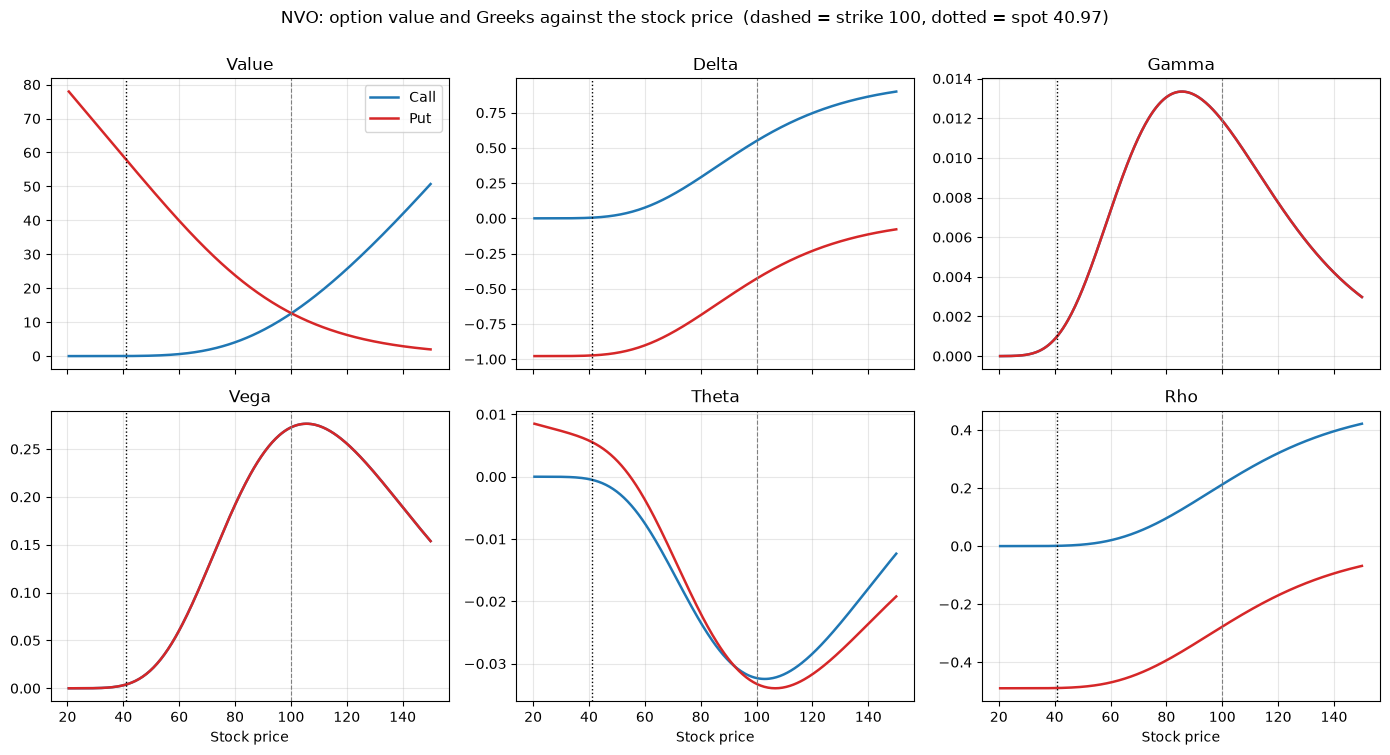

In [ ]:

spots = np.linspace(0.5 * min(S0, K), 1.5 * max(S0, K), 300)  
curves = {kind: bsm_greeks(spots, K, T, r, sigma, q, kind) for kind in ("call", "put")}
values = {kind: bsm_price(spots, K, T, r, sigma, q, kind) for kind in ("call", "put")}

panels = ["Value", "Delta", "Gamma", "Vega", "Theta", "Rho"]
colors = {"call": "#1f77b4", "put": "#d62728"}

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
for ax, name in zip(axes.flat, panels):
    for kind in ("call", "put"):
        y = values[kind] if name == "Value" else curves[kind][name]
        ax.plot(spots, y, color=colors[kind], lw=1.8, label=kind.capitalize())
    ax.axvline(K, color="grey", ls="--", lw=0.8)
    ax.axvline(S0, color="black", ls=":", lw=1)
    ax.set_title(name)
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("Stock price")
axes[0, 0].legend()
fig.suptitle(f"{TICKER}: option value and Greeks against the stock price  "
             f"(dashed = strike {K:,.0f}, dotted = spot {S0:,.2f})", y=1.0)
fig.tight_layout()
plt.show()

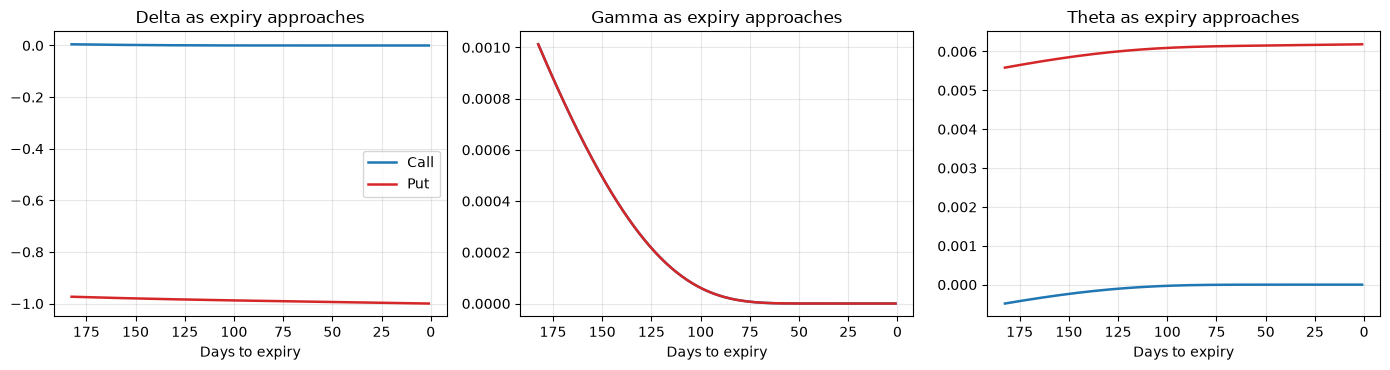

In [ ]:
times = np.linspace(T, 1 / 365, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, name in zip(axes, ["Delta", "Gamma", "Theta"]):
    for kind in ("call", "put"):
        ax.plot(times * 365, bsm_greeks(S0, K, times, r, sigma, q, kind)[name],
                color=colors[kind], lw=1.8, label=kind.capitalize())
    ax.invert_xaxis()
    ax.set(title=f"{name} as expiry approaches", xlabel="Days to expiry")
    ax.grid(alpha=0.3)
axes[0].legend()
fig.tight_layout()
plt.show()

## 5. Implied volatility

Implied volatility is the $\sigma$ that makes the model price equal a price seen in the market.
Newton-Raphson ($\sigma_{n+1} = \sigma_n - \frac{C(\sigma_n) - C_{mkt}}{\nu(\sigma_n)}$) converges fast,
but it diverges when Vega is close to zero (deep in or out of the money). The solver below falls back
to bisection (Brent's method) in that case, and rejects prices outside the no-arbitrage bounds.

In [ ]:
def implied_vol(price, S, K, T, r, q=0.0, kind="call", sigma0=0.3, tol=1e-8, max_iter=100):
    disc_S, disc_K = S * np.exp(-q * T), K * np.exp(-r * T)
    lower = max(disc_S - disc_K, 0) if kind == "call" else max(disc_K - disc_S, 0)
    upper = disc_S if kind == "call" else disc_K
    if not lower <= price < upper:
        return np.nan 

    sigma = sigma0
    for _ in range(max_iter):
        diff = float(bsm_price(S, K, T, r, sigma, q, kind)) - price
        if abs(diff) < tol:
            return sigma
        vega = float(bsm_greeks(S, K, T, r, sigma, q, kind)["Vega"]) * 100
        if vega < 1e-8 or not 1e-4 < sigma - diff / vega < 10:
            break  # Newton step is unreliable here; use bisection instead
        sigma -= diff / vega

    f = lambda s: float(bsm_price(S, K, T, r, s, q, kind)) - price
    return brentq(f, 1e-6, 10.0, xtol=tol)


print(f"Round trip: priced at sigma={sigma:.4%}, implied vol recovered = {implied_vol(call, S0, K, T, r, q):.4%}")

Round trip: priced at sigma=45.8550%, implied vol recovered = 45.8550%


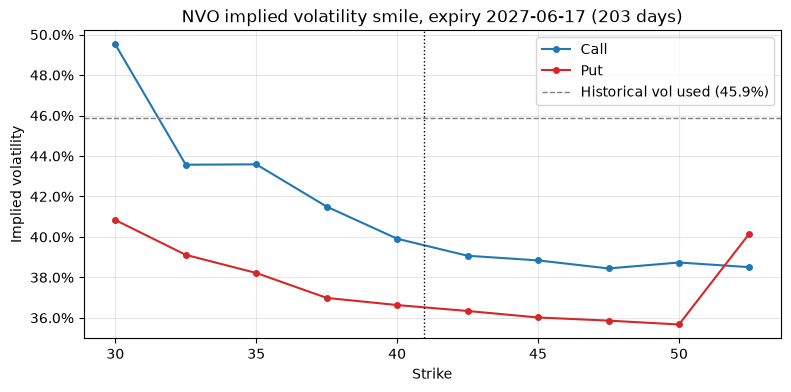

In [ ]:
tk = yf.Ticker(TICKER)
try:
    expiries = tk.options
    target = dt.date.today() + dt.timedelta(days=round(T * 365))
    expiry = min(expiries, key=lambda e: abs(dt.date.fromisoformat(e) - target))
    T_mkt = (dt.date.fromisoformat(expiry) - dt.date.today()).days / 365
    chain = tk.option_chain(expiry)

    rows = []
    for kind, table in (("call", chain.calls), ("put", chain.puts)):
        table = table[(table.strike > 0.7 * S0) & (table.strike < 1.3 * S0)]
        for _, row in table.iterrows():
            mid = (row.bid + row.ask) / 2 if row.bid > 0 and row.ask > 0 else row.lastPrice
            rows.append({"kind": kind, "strike": row.strike, "market price": mid,
                         "implied vol": implied_vol(mid, S0, row.strike, T_mkt, r, q, kind)})
    smile = pd.DataFrame(rows).dropna()

    fig, ax = plt.subplots(figsize=(9, 4))
    for kind, grp in smile.groupby("kind"):
        ax.plot(grp.strike, grp["implied vol"], "o-", ms=4, color=colors[kind], label=kind.capitalize())
    ax.axhline(sigma, color="grey", ls="--", lw=1, label=f"Historical vol used ({sigma:.1%})")
    ax.axvline(S0, color="black", ls=":", lw=1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
    ax.set(title=f"{TICKER} implied volatility smile, expiry {expiry} ({T_mkt * 365:.0f} days)",
           xlabel="Strike", ylabel="Implied volatility")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()
except Exception as exc:
    print(f"Could not load the option chain for {TICKER} ({exc}).")